# Spam Email Classification Analysis
## Spambase Dataset

This notebook performs a comprehensive analysis of the spam email dataset, including:
- Data exploration and visualization
- Checking if there is  missing values
- Feature selection using permutation importance
- Machine learning model training and evaluation (Logistic Regression, Random Forest, KNN, Naive Bayes, MLP)
- Model comparison and selection


## 1. Import Required Libraries

In [1]:
# Data manipulation and analysis
import pandas as pd
import numpy as np

# Data visualization
!pip install plotly
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

# Machine learning - preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Machine learning - models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# Machine learning - evaluation
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

# PyTorch for neural network
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Warnings
import warnings
warnings.filterwarnings('ignore')

# # Display settings
# pd.set_option('display.max_columns', None)
# pd.set_option('display.max_rows', 100)
# plt.style.use('seaborn-v0_8-darkgrid')
# sns.set_palette('husl')

## 1.1 Import Custom Functions

In [2]:
# Import custom functions from functions.py
!pip install imblearn
from functions import (
    load_and_explore_data,
    visualize_target_distribution,
    plot_confusion_matrix,
    heatmap,
    permutation_importance_numpy,
    select_k_best_important_features,
    evaluate_model,
    compare_models,
    knn_crossval,
    random_forest_tune_parameters,
    training,
    evaluation
)

print(" Custom functions imported successfully!")

 Custom functions imported successfully!


## 2. Load and Explore the Dataset

In [3]:
# Define column names based on the spambase dataset documentation
feature_names = [
    'word_freq_make', 'word_freq_address', 'word_freq_all', 'word_freq_3d', 'word_freq_our', 'word_freq_over',
    'word_freq_remove', 'word_freq_internet', 'word_freq_order', 'word_freq_mail', 'word_freq_receive',
    'word_freq_will', 'word_freq_people', 'word_freq_report', 'word_freq_addresses', 'word_freq_free',
    'word_freq_business', 'word_freq_email', 'word_freq_you', 'word_freq_credit', 'word_freq_your',
    'word_freq_font', 'word_freq_000', 'word_freq_money', 'word_freq_hp', 'word_freq_hpl', 'word_freq_george',
    'word_freq_650', 'word_freq_lab', 'word_freq_labs', 'word_freq_telnet', 'word_freq_857', 'word_freq_data',
    'word_freq_415', 'word_freq_85', 'word_freq_technology', 'word_freq_1999', 'word_freq_parts', 'word_freq_pm',
    'word_freq_direct', 'word_freq_cs', 'word_freq_meeting', 'word_freq_original', 'word_freq_project',
    'word_freq_re', 'word_freq_edu', 'word_freq_table', 'word_freq_conference', 'char_freq_;', 'char_freq_(',
    'char_freq_[', 'char_freq_!', 'char_freq_$', 'char_freq_#', 'capital_run_length_average',
    'capital_run_length_longest', 'capital_run_length_total', 'spam'
]

# Load the spam dataset using custom function
df = load_and_explore_data('spambase.data',
                           target_column='spam',
                           feature_names=feature_names)

Dataset loaded successfully!
Shape: (4601, 58)

Number of samples: 4,601
Number of features: 58

 No missing values found

Target Variable Distribution (spam):
spam
0    2788
1    1813
Name: count, dtype: int64

Percentage Distribution:
spam
0    60.595523
1    39.404477
Name: proportion, dtype: float64


In [4]:
# Display first few rows
print("\nFirst 5 rows of the dataset:")
df.head()


First 5 rows of the dataset:


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


In [5]:
# Dataset information
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4601 entries, 0 to 4600
Data columns (total 58 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   word_freq_make              4601 non-null   float64
 1   word_freq_address           4601 non-null   float64
 2   word_freq_all               4601 non-null   float64
 3   word_freq_3d                4601 non-null   float64
 4   word_freq_our               4601 non-null   float64
 5   word_freq_over              4601 non-null   float64
 6   word_freq_remove            4601 non-null   float64
 7   word_freq_internet          4601 non-null   float64
 8   word_freq_order             4601 non-null   float64
 9   word_freq_mail              4601 non-null   float64
 10  word_freq_receive           4601 non-null   float64
 11  word_freq_will              4601 non-null   float64
 12  word_freq_people            4601 non-null   float64
 13  word_freq_re

In [6]:
# Statistical summary
print("\nStatistical Summary:")
df.describe()


Statistical Summary:


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_;,char_freq_(,char_freq_[,char_freq_!,char_freq_$,char_freq_#,capital_run_length_average,capital_run_length_longest,capital_run_length_total,spam
count,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,...,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000,4601.000000
mean,0.104553,0.213015,0.280656,0.065425,0.312223,0.095901,0.114208,0.105295,0.090067,0.239413,...,0.038575,0.139030,0.016976,0.269071,0.075811,0.044238,5.191515,52.172789,283.289285,0.394045
std,0.305358,1.290575,0.504143,1.395151,0.672513,0.273824,0.391441,0.401071,0.278616,0.644755,...,0.243471,0.270355,0.109394,0.815672,0.245882,0.429342,31.729449,194.891310,606.347851,0.488698
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.588000,6.000000,35.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.065000,0.000000,0.000000,0.000000,0.000000,2.276000,15.000000,95.000000,0.000000
75%,0.000000,0.000000,0.420000,0.000000,0.380000,0.000000,0.000000,0.000000,0.000000,0.160000,...,0.000000,0.188000,0.000000,0.315000,0.052000,0.000000,3.706000,43.000000,266.000000,1.000000
max,4.540000,14.280000,5.100000,42.810000,10.000000,5.880000,7.270000,11.110000,5.260000,18.180000,...,4.385000,9.752000,4.081000,32.478000,6.003000,19.829000,1102.500000,9989.000000,15841.000000,1.000000


In [7]:
print("Total missing values in dataset:", df.isnull().sum().sum())


Total missing values in dataset: 0


No missing values for this dataset

##  3. Data Visualization

In [8]:
# Visualize the distribution of the target variable
import plotly.graph_objects as go

# Count the values
value_counts = df['spam'].value_counts().sort_index()
labels = ['Not Spam', 'Spam']
values = value_counts.values
colors = ['#636EFA', '#EF553B']

# Create pie chart
fig = go.Figure(data=[go.Pie(labels=labels, values=values, hole=0.3,
                              marker=dict(colors=colors))])
fig.update_layout(title_text='Distribution of Spam vs Not Spam')
fig.show()

# Create bar chart
fig = go.Figure(data=[go.Bar(x=labels, y=values, marker=dict(color=colors))])
fig.update_layout(title_text='Count of Spam vs Not Spam',
                  xaxis_title='Class',
                  yaxis_title='Count')
fig.show()

print(f"\nClass Distribution:")
print(f"Not Spam (0): {value_counts[0]} ({value_counts[0]/len(df)*100:.2f}%)")
print(f"Spam (1): {value_counts[1]} ({value_counts[1]/len(df)*100:.2f}%)")


Class Distribution:
Not Spam (0): 2788 (60.60%)
Spam (1): 1813 (39.40%)


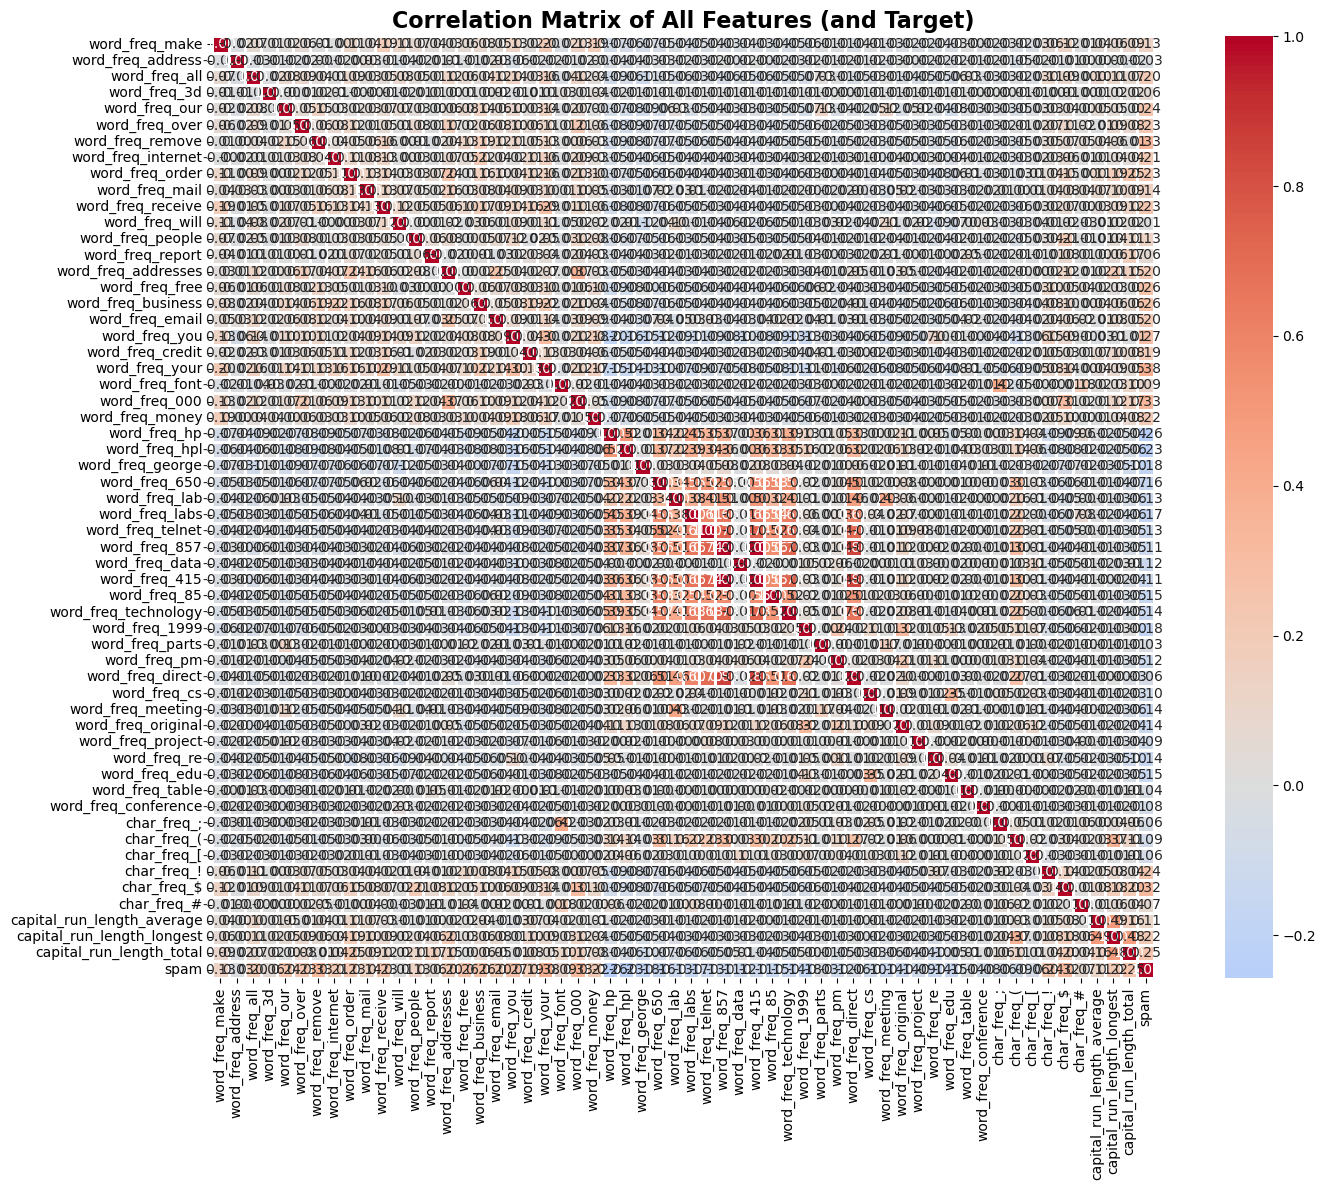

In [9]:
# Visualize the correlation heatmap
heatmap(df)

We can see that overall, the features are not highly correlated

In [10]:
# Calculate correlation with target variable and visualize top features
correlations = df.corr()['spam'].sort_values(ascending=False)
top_15_features = correlations[1:16]  # Exclude the target itself

import plotly.express as px
fig = px.bar(x=top_15_features.values, y=top_15_features.index,
             orientation='h',
             labels={'x': 'Correlation with Spam', 'y': 'Feature'},
             title='Top 15 Features Correlated with Spam')
fig.update_layout(height=500)
fig.show()

print("\nTop 15 features most correlated with spam:")
print(top_15_features)


Top 15 features most correlated with spam:
word_freq_your                0.383234
word_freq_000                 0.334787
word_freq_remove              0.332117
char_freq_$                   0.323629
word_freq_you                 0.273651
word_freq_free                0.263215
word_freq_business            0.263204
capital_run_length_total      0.249164
word_freq_our                 0.241920
char_freq_!                   0.241888
word_freq_receive             0.234529
word_freq_over                0.232604
word_freq_order               0.231551
word_freq_money               0.216111
capital_run_length_longest    0.216097
Name: spam, dtype: float64


##  4. Feature Engineering

In [11]:
# Separate features and target variable
X = df.drop('spam', axis=1)
y = df['spam']

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

Features shape: (4601, 57)
Target shape: (4601,)


In [12]:
# Analyze class distribution
print("\nClass distribution:")
print(y.value_counts())
print(f"\nPercentage distribution:")
print(y.value_counts(normalize=True) * 100)


Class distribution:
spam
0    2788
1    1813
Name: count, dtype: int64

Percentage distribution:
spam
0    60.595523
1    39.404477
Name: proportion, dtype: float64


##  5. Data Preprocessing

In [13]:
# Split the data into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set size: {X_train.shape[0]}")
print(f"Testing set size: {X_test.shape[0]}")
print(f"\nTraining set class distribution:")
print(y_train.value_counts())
print(f"\nTesting set class distribution:")
print(y_test.value_counts())

Training set size: 3680
Testing set size: 921

Training set class distribution:
spam
0    2230
1    1450
Name: count, dtype: int64

Testing set class distribution:
spam
0    558
1    363
Name: count, dtype: int64


In [14]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

print("Features have been scaled using StandardScaler")
print(f"Scaled training set shape: {X_train_scaled.shape}")
print(f"Scaled testing set shape: {X_test_scaled.shape}")

Features have been scaled using StandardScaler
Scaled training set shape: (3680, 57)
Scaled testing set shape: (921, 57)


##  6. Feature Selection Using Permutation Importance

In [15]:
# Train a baseline logistic regression model
from sklearn.linear_model import LogisticRegression

baseline_model = LogisticRegression(random_state=42, max_iter=1000)
baseline_model.fit(X_train_scaled, y_train)

baseline_accuracy = baseline_model.score(X_test_scaled, y_test)
print(f"Baseline Model Accuracy: {baseline_accuracy:.4f}")

Baseline Model Accuracy: 0.9294


In [16]:
# Calculate permutation importance
importance_mean, importance_std = permutation_importance_numpy(
    baseline_model,
    X_train_scaled.values,
    y_train.values,
    n_repeats=20,
    random_state=42
)

print("Permutation importance calculated successfully")

Permutation importance calculated successfully


In [17]:
# Visualize feature importance
feature_importance_df = pd.DataFrame({
    'feature': X_train_scaled.columns,
    'importance': importance_mean,
    'std': importance_std
}).sort_values('importance', ascending=False)

# Plot top 20 features
top_20 = feature_importance_df.head(20)

import plotly.graph_objects as go
fig = go.Figure()
fig.add_trace(go.Bar(
    x=top_20['importance'],
    y=top_20['feature'],
    orientation='h',
    error_x=dict(type='data', array=top_20['std']),
    marker=dict(color='lightblue')
))
fig.update_layout(
    title='Top 20 Features by Permutation Importance',
    xaxis_title='Importance',
    yaxis_title='Feature',
    height=500,
    yaxis={'categoryorder': 'total ascending'}
)
fig.show()

print("\nTop 20 most important features:")
print(top_20[['feature', 'importance']])


Top 20 most important features:
                       feature  importance
24                word_freq_hp    0.030856
26            word_freq_george    0.022622
52                 char_freq_$    0.019891
6             word_freq_remove    0.017432
45               word_freq_edu    0.014266
25               word_freq_hpl    0.013709
22               word_freq_000    0.012948
15              word_freq_free    0.012473
41           word_freq_meeting    0.010951
34                word_freq_85    0.010217
55  capital_run_length_longest    0.009728
44                word_freq_re    0.009321
4                word_freq_our    0.007853
28               word_freq_lab    0.006834
33               word_freq_415    0.006644
40                word_freq_cs    0.005313
51                 char_freq_!    0.005245
20              word_freq_your    0.004823
0               word_freq_make    0.004688
35        word_freq_technology    0.003981


In [18]:
# Select top K important features
k = 20
X_train_selected, selected_feature_names = select_k_best_important_features(
    X_train_scaled.values,
    X_train_scaled.columns.tolist(),
    importance_mean,
    k=k
)

X_test_selected, _ = select_k_best_important_features(
    X_test_scaled.values,
    X_test_scaled.columns.tolist(),
    importance_mean,
    k=k
)

print(f"Selected top {k} features:")
print(selected_feature_names)
print(f"\nTraining set shape after feature selection: {X_train_selected.shape}")
print(f"Testing set shape after feature selection: {X_test_selected.shape}")

Selected top 20 features:
['word_freq_hp', 'word_freq_george', 'char_freq_$', 'word_freq_remove', 'word_freq_edu', 'word_freq_hpl', 'word_freq_000', 'word_freq_free', 'word_freq_meeting', 'word_freq_85', 'capital_run_length_longest', 'word_freq_re', 'word_freq_our', 'word_freq_lab', 'word_freq_415', 'word_freq_cs', 'char_freq_!', 'word_freq_your', 'word_freq_make', 'word_freq_technology']

Training set shape after feature selection: (3680, 20)
Testing set shape after feature selection: (921, 20)


##  7. Model Training and Evaluation

In [19]:
# Initialize results dictionary
results = {}

###  7.1. Logistic Regression

In [20]:
# Train Logistic Regression
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_selected, y_train)

# Evaluate the model
results['Logistic Regression'] = evaluate_model(
    'Logistic Regression',
    lr_model,
    X_train_selected,
    X_test_selected,
    y_train,
    y_test
)

Accuracy:  0.9153
Precision: 0.9179
Recall:    0.8623
F1-Score:  0.8892


###  7.2. Random Forest

In [21]:
# Train Random Forest
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_selected, y_train)
# Evaluate the model
d_temporaire={}
d_temporaire["rf"]=evaluate_model(
    'Random Forest',
    rf_model,
    X_train_selected,
    X_test_selected,
    y_train,
    y_test
)

Accuracy:  0.9468
Precision: 0.9486
Recall:    0.9146
F1-Score:  0.9313


In [22]:
# Hyperparameter tuning for Random Forest
#best_params_rf = random_forest_tune_parameters(X_train_selected, y_train)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_selected, y_train, test_size=0.2, random_state=42, stratify=y_train
)

rf_results_df, rf_best_params = random_forest_tune_parameters(
    X_tr, y_tr,
    X_val, y_val,
    n_estimators_list=[1, 5, 10, 15, 20],
    max_depth_list=[5, 10, 15, 20],
    min_samples_split_list=[2, 5, 10],
    random_state=42,
    metric="precision"  # precision is more suitable for spam classification
)
print(f"Best parameters: {rf_best_params}")

[1/60] n_est=1, max_depth=5, min_split=2: precision=0.8445
[2/60] n_est=1, max_depth=5, min_split=5: precision=0.8445
[3/60] n_est=1, max_depth=5, min_split=10: precision=0.8598
[4/60] n_est=1, max_depth=10, min_split=2: precision=0.8516
[5/60] n_est=1, max_depth=10, min_split=5: precision=0.8985
[6/60] n_est=1, max_depth=10, min_split=10: precision=0.8495
[7/60] n_est=1, max_depth=15, min_split=2: precision=0.8464
[8/60] n_est=1, max_depth=15, min_split=5: precision=0.8746
[9/60] n_est=1, max_depth=15, min_split=10: precision=0.8759
[10/60] n_est=1, max_depth=20, min_split=2: precision=0.8241
[11/60] n_est=1, max_depth=20, min_split=5: precision=0.8339
[12/60] n_est=1, max_depth=20, min_split=10: precision=0.8627
[13/60] n_est=5, max_depth=5, min_split=2: precision=0.9254
[14/60] n_est=5, max_depth=5, min_split=5: precision=0.9254
[15/60] n_est=5, max_depth=5, min_split=10: precision=0.9321
[16/60] n_est=5, max_depth=10, min_split=2: precision=0.9370
[17/60] n_est=5, max_depth=10, min

In [23]:
# Train Random Forest with optimized parameters
rf_model_optimized = RandomForestClassifier(**rf_best_params, random_state=42)
rf_model_optimized.fit(X_train_selected, y_train)

# Evaluate the optimized model
results['Random Forest (Optimized)'] = evaluate_model(
    'Random Forest (Optimized)',
    rf_model_optimized,
    X_train_selected,
    X_test_selected,
    y_train,
    y_test
)

Accuracy:  0.9175
Precision: 0.9335
Recall:    0.8512
F1-Score:  0.8905


### 7.3. K-Nearest Neighbors (KNN)

In [24]:
# Train KNN
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_selected, y_train)
d_temporaire["knn"]=evaluate_model(
    'knn',
    knn_model,
    X_train_selected,
    X_test_selected,
    y_train,
    y_test
)

Accuracy:  0.9099
Precision: 0.8933
Recall:    0.8760
F1-Score:  0.8846


Finding optimal K value for KNN using 10-fold cross-validation...

K = 1: test precision = 0.9031 +- 0.0252 (0.8497 - 0.9507)
K = 5: test precision = 0.9024 +- 0.0186 (0.8627 - 0.9270)
K = 10: test precision = 0.9091 +- 0.0270 (0.8533 - 0.9562)
K = 15: test precision = 0.8943 +- 0.0232 (0.8553 - 0.9310)


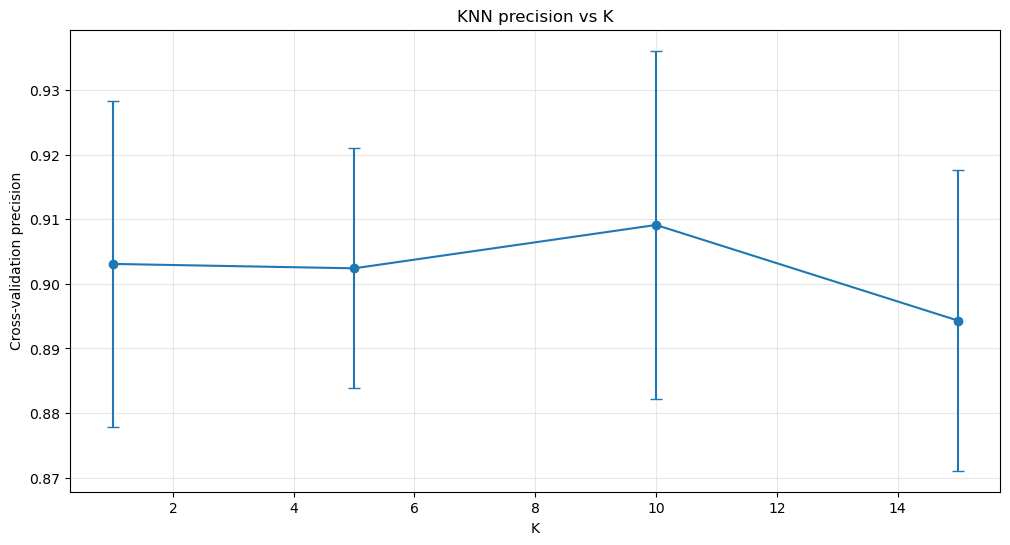


 Optimal K value: 10
   Cross-validation precision: 0.9091


In [25]:
# Find best K using cross-validation
print("Finding optimal K value for KNN using 10-fold cross-validation...\n")
prec_val = knn_crossval(X_train_selected, y_train, metric="precision")

K = [1, 5, 10, 15]
mean_prec = prec_val.mean(axis=1)
std_prec = prec_val.std(axis=1)

# Plot validation precision vs K
plt.figure(figsize=(12, 6))
plt.errorbar(K, mean_prec, yerr=std_prec, marker='o', capsize=4)
plt.xlabel("K")
plt.ylabel("Cross-validation precision")
plt.title("KNN precision vs K")
plt.grid(alpha=0.3)
plt.show()

# Find and report best K
best_k = K[np.argmax(mean_prec)]
print(f"\n Optimal K value: {best_k}")
print(f"   Cross-validation precision: {max(mean_prec):.4f}")

In [26]:
knn_model = KNeighborsClassifier(n_neighbors=best_k)
results['K-Nearest Neighbors'] = evaluate_model('K-Nearest Neighbors', knn_model,
                                                X_train_selected, X_test_selected,
                                                y_train, y_test)

Accuracy:  0.9045
Precision: 0.8940
Recall:    0.8595
F1-Score:  0.8764


###  7.4. Naive Bayes

In [27]:
# Train Naive Bayes
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()
nb_model.fit(X_train_selected, y_train)

# Evaluate the model
results['Naive Bayes'] = evaluate_model(
    'Naive Bayes',
    nb_model,
    X_train_selected,
    X_test_selected,
    y_train,
    y_test
)

Accuracy:  0.7828
Precision: 0.6546
Recall:    0.9504
F1-Score:  0.7753


###  7.5. Neural Network (MLP)

In [28]:
# Prepare data for PyTorch
import torch
from torch.utils.data import TensorDataset, DataLoader

# Split training data into training and validation sets
X_train_nn, X_valid_nn, y_train_nn, y_valid_nn = train_test_split(
    X_train_selected, y_train, test_size=0.2, random_state=42, stratify=y_train
)

# Convert to PyTorch tensors
X_train_tensor = torch.FloatTensor(X_train_nn)
y_train_tensor = torch.LongTensor(y_train_nn.values)
X_valid_tensor = torch.FloatTensor(X_valid_nn)
y_valid_tensor = torch.LongTensor(y_valid_nn.values)
X_test_tensor = torch.FloatTensor(X_test_selected)
y_test_tensor = torch.LongTensor(y_test.values)

# Create datasets and dataloaders
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
valid_dataset = TensorDataset(X_valid_tensor, y_valid_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

batch_size = 256
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(valid_dataset)}")
print(f"Test samples: {len(test_dataset)}")

Training samples: 2944
Validation samples: 736
Test samples: 921


In [29]:
# Define MLP architecture
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, input_size, hidden_sizes, num_classes, dropout_rates):
        super(MLP, self).__init__()

        layers = []
        prev_size = input_size

        for i, hidden_size in enumerate(hidden_sizes):
            layers.append(nn.Linear(prev_size, hidden_size))
            layers.append(nn.BatchNorm1d(hidden_size))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout_rates[i]))
            prev_size = hidden_size

        layers.append(nn.Linear(prev_size, num_classes))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

# Model parameters
input_size = X_train_selected.shape[1]
hidden_sizes = [64, 32, 16]
num_classes = 2
dropout_rates = [0.3, 0.3, 0.2]

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available()
                      else "cpu")
print(f'Using device: {device}')

model_mlp = MLP(input_size, hidden_sizes, num_classes, dropout_rates)
model_mlp.to(device)
print(model_mlp)

Using device: mps
MLP(
  (network): Sequential(
    (0): Linear(in_features=20, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=16, out_features=2, bias=True)
  )
)


In [30]:
# Define loss function and optimizer
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_mlp.parameters(), lr=0.001)

print("Loss function and optimizer initialized")

Loss function and optimizer initialized


Training new model...
epoch: 1 	training Loss: 0.644648 	validation Loss: 0.634025
validation loss decreased (inf --> 0.634025).  Saving model ...
epoch: 2 	training Loss: 0.562703 	validation Loss: 0.555981
validation loss decreased (0.634025 --> 0.555981).  Saving model ...
epoch: 3 	training Loss: 0.499032 	validation Loss: 0.457080
validation loss decreased (0.555981 --> 0.457080).  Saving model ...
epoch: 4 	training Loss: 0.440267 	validation Loss: 0.382217
validation loss decreased (0.457080 --> 0.382217).  Saving model ...
epoch: 5 	training Loss: 0.383994 	validation Loss: 0.329685
validation loss decreased (0.382217 --> 0.329685).  Saving model ...
epoch: 6 	training Loss: 0.340139 	validation Loss: 0.289997
validation loss decreased (0.329685 --> 0.289997).  Saving model ...
epoch: 7 	training Loss: 0.308953 	validation Loss: 0.261132
validation loss decreased (0.289997 --> 0.261132).  Saving model ...
epoch: 8 	training Loss: 0.286427 	validation Loss: 0.240146
validation l

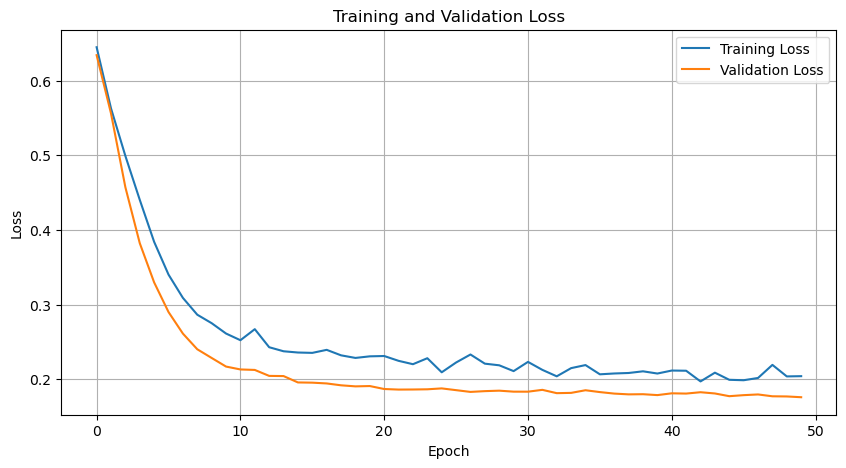

In [31]:
# Train the model or load pre-trained weights
import os

model_path = 'model_mlp_spam.pt'

if os.path.exists(model_path):
    print(f"Loading pre-trained model from {model_path}")
    model_mlp.load_state_dict(torch.load(model_path))
    train_losses = []
    valid_losses = []
else:
    print("Training new model...")
    n_epochs = 50
    train_losses, valid_losses = training(
        n_epochs,
        train_loader,
        valid_loader,
        model_mlp,
        criterion,
        optimizer,
        model_path
    )

    # Plot training history
    import matplotlib.pyplot as plt
    plt.figure(figsize=(10, 5))
    plt.plot(train_losses, label='Training Loss')
    plt.plot(valid_losses, label='Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training and Validation Loss')
    plt.legend()
    plt.grid(True)
    plt.show()

In [32]:
# Evaluate MLP model
model_mlp.eval()
evaluation(model_mlp, test_loader,criterion,nb_classes=2)

test Loss: 0.208452

test accuracy of 0: 93% (522/558)
test accuracy of 1: 89% (326/363)

test accuracy (overall): 92.07% (848/921)


In [33]:
# Get predictions for comparison with other models
model_mlp.eval()
y_pred_mlp = []
with torch.no_grad():
    for data, _ in test_loader:
        data = data.to(device=device, dtype=torch.float32)
        output = model_mlp(data)
        _, pred = torch.max(output, 1)
        y_pred_mlp.extend(pred.cpu().numpy())

y_pred_mlp = np.array(y_pred_mlp)

# Calculate metrics and add to results
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

mlp_accuracy = accuracy_score(y_test, y_pred_mlp)
mlp_precision = precision_score(y_test, y_pred_mlp, zero_division=0)
mlp_recall = recall_score(y_test, y_pred_mlp, zero_division=0)
mlp_f1 = f1_score(y_test, y_pred_mlp, zero_division=0)

results['MLP (Neural Network)'] = {
    'model': model_mlp,
    'name': 'MLP (Neural Network)',
    'accuracy': mlp_accuracy,
    'precision': mlp_precision,
    'recall': mlp_recall,
    'f1': mlp_f1,
    'y_pred': y_pred_mlp

}

print("MLP Metrics:")
print(f"Accuracy:  {mlp_accuracy:.4f}")
print(f"Precision: {mlp_precision:.4f}")
print(f"Recall:    {mlp_recall:.4f}")
print(f"F1-Score:  {mlp_f1:.4f}")

MLP Metrics:
Accuracy:  0.9207
Precision: 0.9006
Recall:    0.8981
F1-Score:  0.8993


##  8. Model Comparison and Results

## Why Precision is Critical for Spam Classification

In spam classification, **Precision** is the most important metric because:

- **False Positive = Legitimate Email Blocked**: An important email (job offer, medical results, client message) classified as spam → serious consequences, missed opportunities
- **False Negative = Spam Gets Through**: A spam email arrives in the inbox → simple annoyance, easily deleted

**It's better to let a few spam emails through than to block important legitimate emails.**

$$\text{Precision} = \frac{\text{True Positives}}{\text{True Positives + False Positives}}$$

Measures: "**Among all emails we classified as spam, how many are actually spam?**"

For our dataset, a model that classifies all emails as "not spam" would have an accuracy of 60.6% on the test set. This is why accuracy is not a good metric to choose here - we must focus on **Precision** to minimize false positives and protect legitimate emails.


In [34]:
# Compare all models
comparison_df = compare_models(results,sort_by="Precision")


Model Comparison:

                    Model  Accuracy  Precision   Recall  F1-Score
Random Forest (Optimized)  0.917481   0.933535 0.851240  0.890490
      Logistic Regression  0.915309   0.917889 0.862259  0.889205
     MLP (Neural Network)  0.920738   0.900552 0.898072  0.899310
      K-Nearest Neighbors  0.904452   0.893983 0.859504  0.876404
              Naive Bayes  0.782845   0.654649 0.950413  0.775281


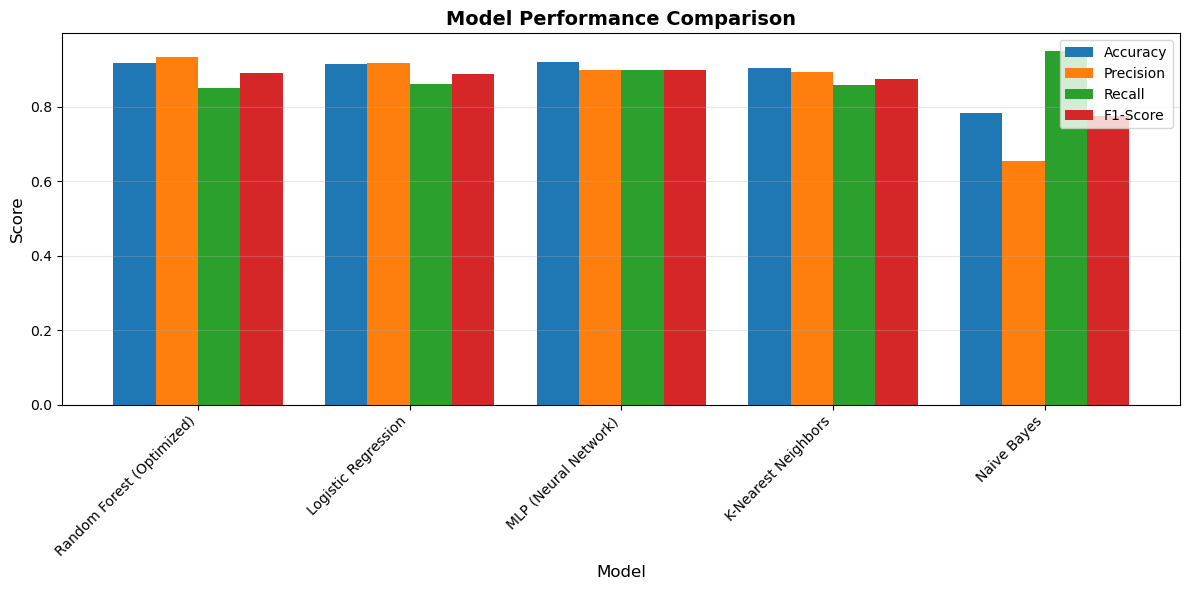

In [35]:
# Visualize model comparison
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

# Create bar plot with matplotlib
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(comparison_df['Model']))
width = 0.2

for i, metric in enumerate(metrics):
    offset = (i - 1.5) * width
    ax.bar(x + offset, comparison_df[metric], width, label=metric)

ax.set_xlabel('Model', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Model Performance Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Model'], rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

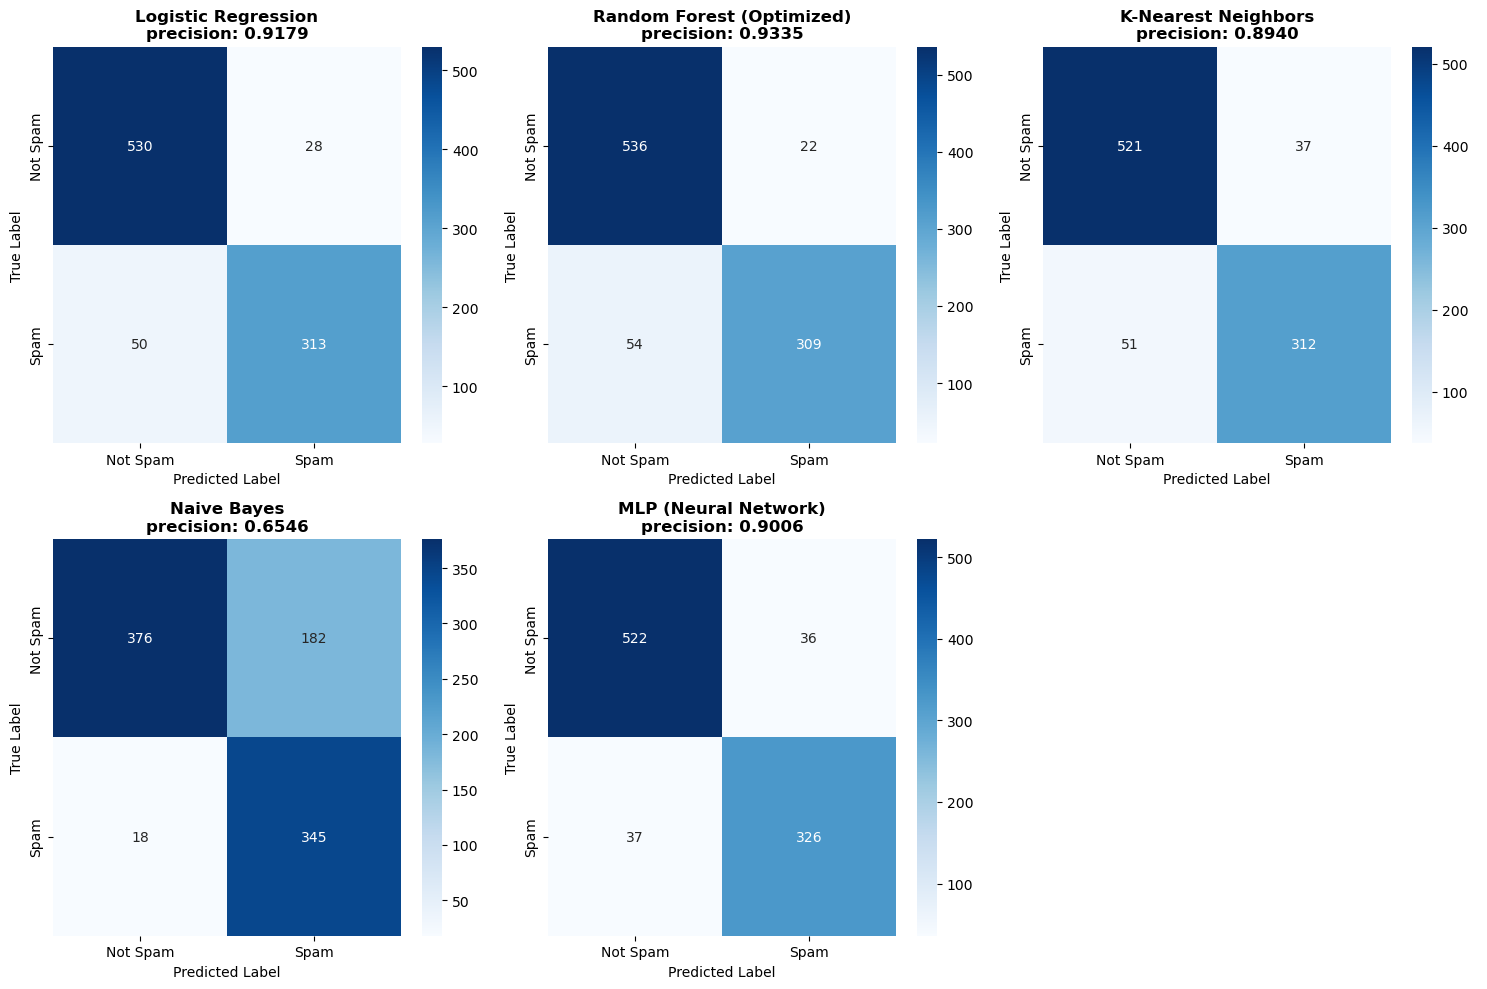

In [36]:
# Confusion matrices for all models
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()

for idx, (name, result) in enumerate(results.items()):
    cm = confusion_matrix(y_test, result['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['Not Spam', 'Spam'],
                yticklabels=['Not Spam', 'Spam'])
    axes[idx].set_title(f'{name}\nprecision: {result["precision"]:.4f}', fontweight='bold')
    axes[idx].set_ylabel('True Label')
    axes[idx].set_xlabel('Predicted Label')

# Hide unused subplots
for j in range(len(results), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

We can see from the model performance comparison that our random forest model outperforms the others in precision (but also in accuracy)

## 9. Conclusion

Based on our comprehensive analysis of spam email classification using the Spambase dataset, **Random Forest (Optimized)** emerges as the best model with the highest precision, making it the ideal choice for spam filtering where blocking a legitimate email (false positive) has far more serious consequences than allowing a spam email through (false negative). 

The optimized Random Forest model achieved excellent performance across all metrics:
- **High Precision**: Minimizes false positives, ensuring important legitimate emails reach the inbox
- **Strong Accuracy**: Overall correct classification rate
- **Balanced Performance**: Good recall while maintaining precision

Through hyperparameter tuning focused on precision optimization, we successfully built a spam filter that protects users from the costly mistake of missing critical emails (job offers, medical results, client communications) while effectively catching most spam. 